In [135]:
from google.colab import drive
import pandas as pd
import numpy as np

drive.mount('/content/drive')

url = "/content/drive/MyDrive/Colab Notebooks/bigdata/"
df = pd.read_csv(url+"hotel_bookings.csv")
df.info()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hotel                   457 non-null    object 
 1   lead_time               457 non-null    int64  
 2   arrival_month           457 non-null    object 
 3   adults                  457 non-null    int64  
 4   children                449 non-null    float64
 5   babies                  457 non-null    int64  
 6   country                 450 non-null    object 
 7   market_segment          457 non-null    object 
 8   deposit_type            453 non-null    object 
 9   customer_type           457 non-null    object 
 10  adr                     452 non-null    float64
 11  previous_cancellations  457 non-null    int64  
 12  special_requests   

In [136]:
df.sample(10)

,hotel,lead_time,arrival_month,adults,children,babies,country,market_segment,deposit_type,customer_type,adr,previous_cancellations,special_requests,is_canceled
222,City Hotel,176,May,2,0.0,0,USA,Corporate,Refundable,Transient,80.0,1,2,0
199,Resort Hotel,94,Dec,3,2.0,0,JPN,Online,No Deposit,Group,345.0,4,3,1
232,City Hotel,182,May,2,1.0,0,JPN,Agent,Refundable,Transient,114.0,3,4,1
148,Resort Hotel,284,Jun,4,1.0,0,KOR,Offline,No Deposit,Transient,57.0,3,2,1
451,City Hotel,228,Feb,2,1.0,0,KOR,Online,Non Refund,Contract,181.0,1,4,0
12,Resort Hotel,34,Jan,2,0.0,0,FRA,Online,Non Refund,Group,222.0,5,1,1
197,City Hotel,284,Apr,3,1.0,0,FRA,Agent,No Deposit,Transient,345.0,1,2,1
102,City Hotel,349,Nov,2,0.0,0,GBR,Corporate,Non Refund,Contract,252.0,5,2,1
68,City Hotel,320,Oct,3,2.0,0,KOR,Corporate,Non Refund,Transient,305.0,1,3,0
420,City Hotel,82,Aug,1,1.0,0,KOR,Corporate,Refundable,Group,146.0,4,0,1


In [137]:
from sklearn.preprocessing import LabelEncoder
#child 와 baby를 합침(baby의 표본이 매우 적음)
df["has_kids"] = ((df["children"].fillna(0) + df["babies"]) > 0).astype(int)
df = df.drop(columns=["children", "babies"])

'''
#previous_cancellations
df["prev_cancel_2plus"] = (df["previous_cancellations"] >= 2).astype(int)
df = df.drop(columns=["previous_cancellations"])   # 바꾸는 경우
'''
# 1. 범주형 변수 결측치 처리 (결측을 'Unknown' 범주로 따로 둠)
for col in ["country", "deposit_type"]:
    df[col] = df[col].fillna("Unknown")

# 2. 월 -> 계절로 묶기 (아직 문자열 범주)
season_map = {
    "Dec": "Winter", "Jan": "Winter", "Feb": "Winter",
    "Mar": "Spring", "Apr": "Spring", "May": "Spring",
    "Jun": "Summer", "Jul": "Summer", "Aug": "Summer",
    "Sep": "Fall",   "Oct": "Fall",   "Nov": "Fall",
}
df["season"] = df["arrival_month"].map(season_map)
df = df.drop(columns=["arrival_month"])
# 4. Label Encoding

cat_cols = ["hotel", "deposit_type", "market_segment",
            "customer_type", "country", "season"]
encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    encoders[col] = le
    print(col, dict(zip(le.classes_, le.transform(le.classes_))))


'''
# 3. 기준 범주 지정 (drop_first=True 일 때 빠지는 범주)
#    -> 계수를 "기준 범주 대비 효과"로 해석하게 되므로 의미 있는 값으로 고름
baseline = {
    "hotel": "City Hotel",
    "deposit_type": "No Deposit",
    "market_segment": "Online",
    "customer_type": "Transient",
    "country": "KOR",
    "season": "Fall",
}
for col, base in baseline.items():
    cats = [base] + sorted(c for c in df[col].unique() if c != base)
    df[col] = pd.Categorical(df[col], categories=cats)

# 4. 원-핫 인코딩 (같은 변수에서 나온 열은 항상 같이 사용)
cat_cols = list(baseline.keys())
df_encoded = pd.get_dummies(df.drop(columns=["arrival_month"]),
                            columns=cat_cols, drop_first=True, dtype=int)

print(df_encoded.shape)
print(df_encoded.columns.tolist())
print(df_encoded.head())

df_encoded.to_csv("hotel_bookings_encoded.csv", index=False)
df = df_encoded
'''

hotel {'City Hotel': np.int64(0), 'Resort Hotel': np.int64(1)}
deposit_type {'No Deposit': np.int64(0), 'Non Refund': np.int64(1), 'Refundable': np.int64(2), 'Unknown': np.int64(3)}
market_segment {'Agent': np.int64(0), 'Corporate': np.int64(1), 'Offline': np.int64(2), 'Online': np.int64(3)}
customer_type {'Contract': np.int64(0), 'Group': np.int64(1), 'Transient': np.int64(2)}
country {'CHN': np.int64(0), 'FRA': np.int64(1), 'GBR': np.int64(2), 'JPN': np.int64(3), 'KOR': np.int64(4), 'USA': np.int64(5), 'Unknown': np.int64(6)}
season {'Fall': np.int64(0), 'Spring': np.int64(1), 'Summer': np.int64(2), 'Winter': np.int64(3)}


'\n# 3. 기준 범주 지정 (drop_first=True 일 때 빠지는 범주)\n#    -> 계수를 "기준 범주 대비 효과"로 해석하게 되므로 의미 있는 값으로 고름\nbaseline = {\n    "hotel": "City Hotel",\n    "deposit_type": "No Deposit",\n    "market_segment": "Online",\n    "customer_type": "Transient",\n    "country": "KOR",\n    "season": "Fall",\n}\nfor col, base in baseline.items():\n    cats = [base] + sorted(c for c in df[col].unique() if c != base)\n    df[col] = pd.Categorical(df[col], categories=cats)\n\n# 4. 원-핫 인코딩 (같은 변수에서 나온 열은 항상 같이 사용)\ncat_cols = list(baseline.keys())\ndf_encoded = pd.get_dummies(df.drop(columns=["arrival_month"]),\n                            columns=cat_cols, drop_first=True, dtype=int)\n\nprint(df_encoded.shape)\nprint(df_encoded.columns.tolist())\nprint(df_encoded.head())\n\ndf_encoded.to_csv("hotel_bookings_encoded.csv", index=False)\ndf = df_encoded\n'

In [138]:
df.info()

#'adr'의 이상치 제거(값이 음수이고 하나뿐), 결측치는 중앙값으로 대체(표본수 확보)
import numpy as np
df['adr'] = df['adr'].fillna(df['adr'].median())           #결측치 5개 중앙값으로 대체
#df = df[df['adr'].between(50, 350)].copy()                 #이상치 4개 제거

df['is_canceled']



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   hotel                   457 non-null    int64  
 1   lead_time               457 non-null    int64  
 2   adults                  457 non-null    int64  
 3   country                 457 non-null    int64  
 4   market_segment          457 non-null    int64  
 5   deposit_type            457 non-null    int64  
 6   customer_type           457 non-null    int64  
 7   adr                     452 non-null    float64
 8   previous_cancellations  457 non-null    int64  
 9   special_requests        457 non-null    int64  
 10  is_canceled             457 non-null    int64  
 11  has_kids                457 non-null    int64  
 12  season                  457 non-null    int64  
dtypes: float64(1), int64(12)
memory usage: 46.5 KB


,is_canceled
0,0
1,1
2,1
3,1
4,1
...,...
452,1
453,1
454,0
455,0


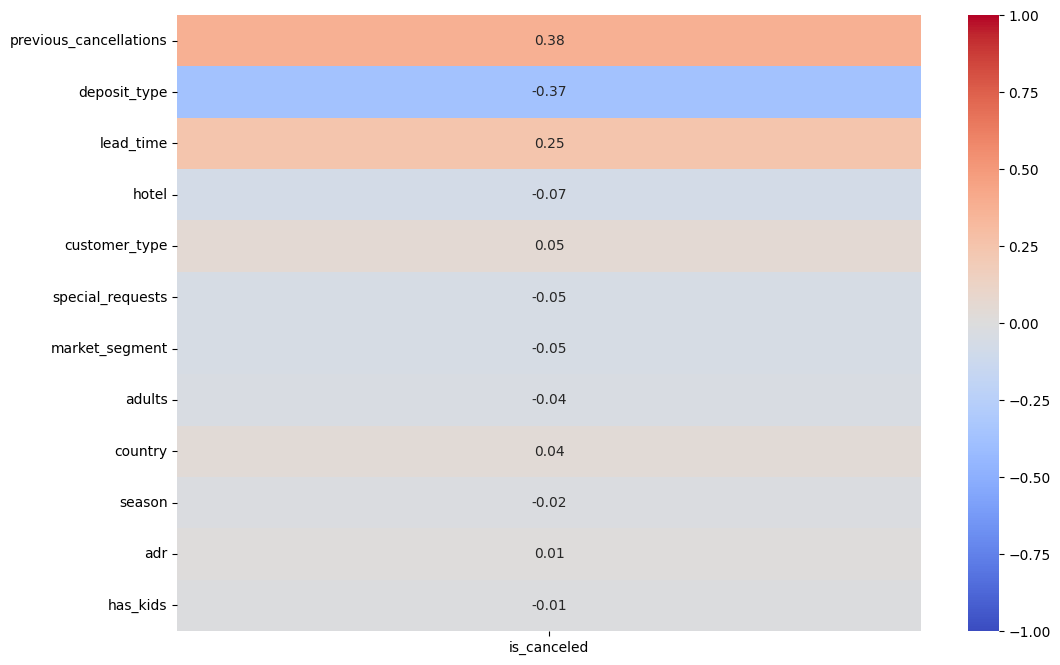

In [139]:
import matplotlib.pyplot as plt
import seaborn as sns

# 숫자형 컬럼끼리 상관계수 계산
corr = df.corr(numeric_only=True)['is_canceled'].drop('is_canceled')
corr = corr.loc[corr.abs().sort_values(ascending=False).index]
corr = corr.to_frame()
# 히트맵
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,       # 상관계수 표시
    cmap='coolwarm',  # 양수는 붉은색, 음수는 푸른색 계열
    fmt='.2f',        # 소수점 둘째 자리까지
    vmin=-1,
    vmax=1
)

plt.show()


-이상치와 결측치를 포함해서 돌린것과 아닌것의 차이

-어느 모델이 가장 적합한지

In [140]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["is_canceled"])
y = df["is_canceled"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(319, 12) (138, 12)


In [141]:
#결정트리
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

dt = DecisionTreeClassifier(max_depth =4 , random_state=42)
dt.fit(X_train,y_train)
predD = dt.predict(X_test)

print("훈련점수:",dt.score(X_train,y_train))
print("테스트점수:",dt.score(X_test,y_test))
#훈련점수: 0.9310344827586207
#테스트점수: 0.927536231884058
print("정확도:", accuracy_score(y_test, predD))
print(classification_report(y_test, predD))
#정확도: 0.927536231884058

훈련점수: 0.9310344827586207
테스트점수: 0.927536231884058
정확도: 0.927536231884058
              precision    recall  f1-score   support

           0       0.89      0.89      0.89        47
           1       0.95      0.95      0.95        91

    accuracy                           0.93       138
   macro avg       0.92      0.92      0.92       138
weighted avg       0.93      0.93      0.93       138



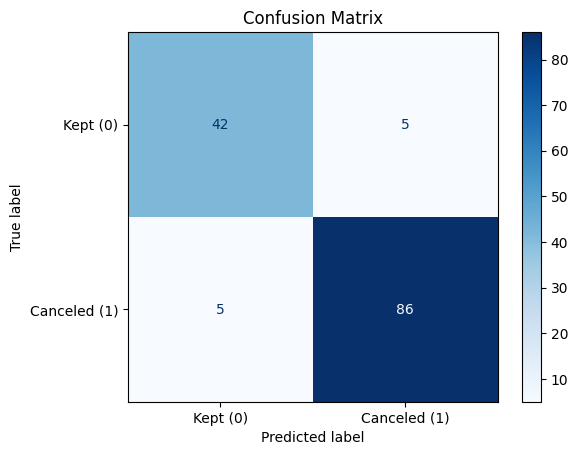

In [143]:
from sklearn.metrics import ConfusionMatrixDisplay
ConfusionMatrixDisplay.from_estimator(
    dt, X_test, y_test,
    display_labels=["Kept (0)", "Canceled (1)"],
    cmap="Blues",
)
plt.title("Confusion Matrix")
plt.show()

In [144]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rf = RandomForestClassifier(n_estimators=200, max_depth=5, random_state=42)
rf.fit(X_train, y_train)

print("훈련점수:", rf.score(X_train, y_train))
print("테스트점수:", rf.score(X_test, y_test))
#훈련점수: 1.0
#테스트점수: 0.9347826086956522    과적합이므로 교차검증 필요

print(classification_report(y_test, rf.predict(X_test)))

훈련점수: 1.0
테스트점수: 0.9347826086956522
              precision    recall  f1-score   support

           0       0.93      0.87      0.90        47
           1       0.94      0.97      0.95        91

    accuracy                           0.93       138
   macro avg       0.93      0.92      0.93       138
weighted avg       0.93      0.93      0.93       138



In [147]:
#최적 파라미터 탐색
from sklearn.model_selection import GridSearchCV

params = {
     'n_estimators': [100, 200],
    'max_depth': [3, 5, 7],
    'min_samples_leaf': [1, 2, 4],
    'min_samples_split': [2, 5]
}

grid = GridSearchCV(
    estimator=rf,
    param_grid=params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    return_train_score=True
)

grid.fit(X_train, y_train)

print("최고 교차검증 점수:", round(grid.best_score_, 4))
print("최적 파라미터:", grid.best_params_)
print("훈련 점수:", round(grid.best_estimator_.score(X_train, y_train), 4))
print("테스트 점수:", round(grid.best_estimator_.score(X_test, y_test), 4))

최고 교차검증 점수: 0.9404
최적 파라미터: {'max_depth': 5, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}
훈련 점수: 0.9969
테스트 점수: 0.9275


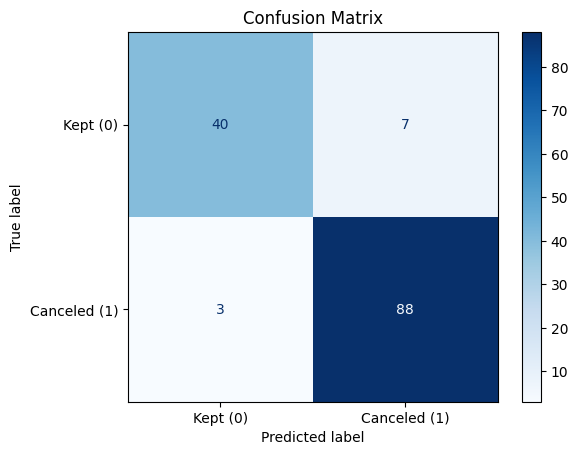

              precision    recall  f1-score   support

           0       0.89      0.89      0.89        47
           1       0.95      0.95      0.95        91

    accuracy                           0.93       138
   macro avg       0.92      0.92      0.92       138
weighted avg       0.93      0.93      0.93       138



In [150]:
from sklearn.metrics import ConfusionMatrixDisplay
best_rf = grid.best_estimator_
ConfusionMatrixDisplay.from_estimator(
    best_rf, X_test, y_test,
    display_labels=["Kept (0)", "Canceled (1)"],
    cmap="Blues",
)
plt.title("Confusion Matrix")
plt.show()
print(classification_report(y_test, predD))